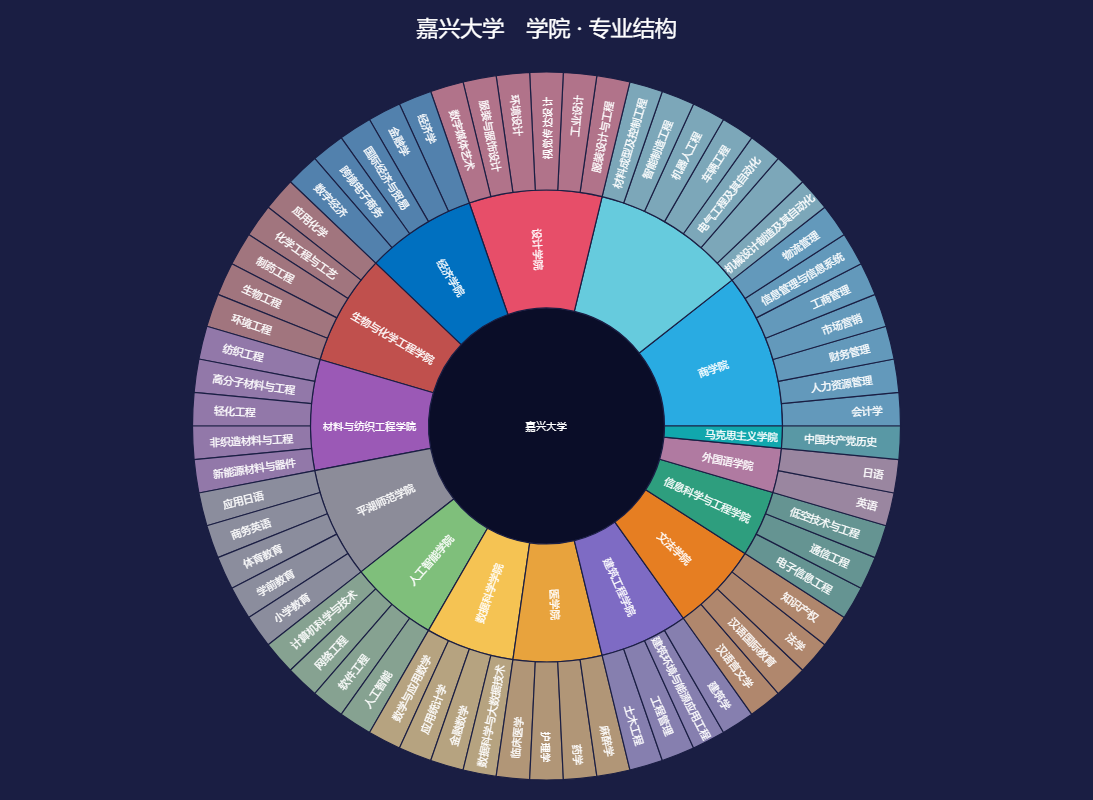

学院 15 专业 66 节点 82


In [5]:
import plotly.graph_objects as go
from plotly.colors import hex_to_rgb

MAJORS = {
    "经济学院": ["经济学", "金融学", "国际经济与贸易", "跨境电子商务", "数字经济"],
    "商学院": ["会计学", "人力资源管理", "财务管理", "市场营销", "工商管理",
              "信息管理与信息系统", "物流管理"],
    "马克思主义学院": ["中国共产党历史"],
    "机械工程学院（机器人工程学院）": ["机械设计制造及其自动化", "机械设计制造及其自动化（中外合作办学）",
                                "电气工程及其自动化", "车辆工程", "机器人工程",
                                "智能制造工程", "材料成型及控制工程"],
    "信息科学与工程学院": ["电子信息工程", "通信工程", "低空技术与工程"],
    "人工智能学院": ["计算机科学与技术", "网络工程", "软件工程", "人工智能"],
    "数据科学学院": ["数学与应用数学", "应用统计学", "金融数学", "数据科学与大数据技术"],
    "医学院": ["临床医学", "护理学", "药学", "麻醉学"],
    "设计学院": ["服装设计与工程", "工业设计", "视觉传达设计", "环境设计",
              "服装与服饰设计", "数字媒体艺术"],
    "生物与化学工程学院": ["应用化学", "化学工程与工艺", "制药工程", "生物工程", "环境工程"],
    "材料与纺织工程学院": ["纺织工程", "高分子材料与工程", "轻化工程", "非织造材料与工程",
                    "新能源材料与器件"],
    "建筑工程学院": ["土木工程", "工程管理", "建筑环境与能源应用工程", "建筑学"],
    "文法学院": ["汉语言文学", "汉语国际教育", "法学", "知识产权"],
    "外国语学院": ["英语", "日语"],
    "平湖师范学院": ["应用日语", "商务英语", "体育教育", "学前教育", "小学教育"],}

ROOT = "嘉兴大学"
FONT = "Microsoft YaHei"
BG, TEXT = "#1A1E43", "#FFFFFF"
PALETTE = ["#0070C0", "#29ABE2", "#11A7AD", "#66CBDD", "#2E9E7E",
           "#7FBF7B", "#F5C353", "#E8A33D", "#E74E69", "#C0504D",
           "#9B59B6", "#7E6BC4", "#E67E22", "#B07AA1", "#8C8C99"]


def lighten(c, f=0.42):
    r, g, b = hex_to_rgb(c)
    return "rgb(%d,%d,%d)" % (round(r + (255 - r) * f),
                              round(g + (255 - g) * f),
                              round(b + (255 - b) * f))


ids, labels, parents, values, colors = (
    ["root"], [ROOT], [""], [sum(len(v) for v in MAJORS.values())], ["#0A0D28"])
for i, (col, ms) in enumerate(MAJORS.items()):
    cid, base = "c%d" % i, PALETTE[i % len(PALETTE)]
    ids.append(cid); labels.append(col); parents.append("root"); values.append(len(ms)); colors.append(base)
    for m in ms:
        ids.append("%s/%s" % (cid, m)); labels.append(m); parents.append(cid); values.append(1)
        colors.append(lighten(base))

fig = go.Figure(go.Sunburst(
    ids=ids, labels=labels, parents=parents, values=values,
    branchvalues="total", maxdepth=3,
    marker=dict(colors=colors, line=dict(color=BG, width=1.2)),
    textinfo="label", insidetextorientation="radial",
    textfont=dict(family=FONT, size=11, color=TEXT),
    hovertemplate="<b>%{label}</b><br>占本级 %{percentParent:.1%}<extra></extra>",))
fig.update_layout(
    title=dict(text="%s　学院 · 专业结构" % ROOT, x=0.5, xanchor="center",
               font=dict(family=FONT, size=22, color=TEXT)),
    paper_bgcolor=BG, font=dict(family=FONT, color=TEXT),
    width=900, height=800, margin=dict(l=20, r=20, t=72, b=20),
    uniformtext=dict(minsize=8, mode="hide"),)

fig.show()

fig.write_html("sunburst.html", include_plotlyjs="cdn", config={"displayModeBar": False})
print("学院", len(MAJORS), "专业", sum(len(v) for v in MAJORS.values()), "节点", len(ids))